In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:


df = pd.read_csv("employee_attrition_raw.csv")

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

Dataset loaded successfully!
Shape of dataset: (1470, 35)


In [3]:


df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [4]:


print("Columns in the dataset:")
print(df.columns.tolist())

Columns in the dataset:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [5]:


df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [6]:


missing_values = df.isnull().sum()

print("Missing values by column:")
print(missing_values[missing_values > 0])

Missing values by column:
Series([], dtype: int64)


In [7]:


duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


In [8]:


df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [9]:


numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_columns = df.select_dtypes(include=['object']).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Categorical columns:
['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']


In [10]:

print("Attrition value counts:")
print(df['Attrition'].value_counts())

print("\nAttrition percentages:")
print(df['Attrition'].value_counts(normalize=True) * 100)

Attrition value counts:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition percentages:
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


In [11]:

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


Attrition:
['Yes' 'No']

BusinessTravel:
['Travel_Rarely' 'Travel_Frequently' 'Non-Travel']

Department:
['Sales' 'Research & Development' 'Human Resources']

EducationField:
['Life Sciences' 'Other' 'Medical' 'Marketing' 'Technical Degree'
 'Human Resources']

Gender:
['Female' 'Male']

JobRole:
['Sales Executive' 'Research Scientist' 'Laboratory Technician'
 'Manufacturing Director' 'Healthcare Representative' 'Manager'
 'Sales Representative' 'Research Director' 'Human Resources']

MaritalStatus:
['Single' 'Married' 'Divorced']

Over18:
['Y']

OverTime:
['Yes' 'No']


In [12]:


constant_columns = [column for column in df.columns if df[column].nunique() == 1]

print("Constant columns:")
print(constant_columns)

Constant columns:
['EmployeeCount', 'Over18', 'StandardHours']


In [13]:


columns_to_drop = [
    'EmployeeCount',
    'EmployeeNumber',
    'Over18',
    'StandardHours'
]

df_clean = df.drop(columns=columns_to_drop)

print("Removed columns:")
print(columns_to_drop)

print("\nNew dataset shape:", df_clean.shape)

Removed columns:
['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours']

New dataset shape: (1470, 31)


In [14]:


print("Remaining columns:")
print(df_clean.columns.tolist())

Remaining columns:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [15]:


categorical_clean = df_clean.select_dtypes(include=['object']).columns.tolist()

for column in categorical_clean:
    print(f"\n{column}:")
    print(df_clean[column].value_counts())


Attrition:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

BusinessTravel:
BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64

Department:
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

EducationField:
EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64

Gender:
Gender
Male      882
Female    588
Name: count, dtype: int64

JobRole:
JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64

MaritalStatus:
MaritalStatus
Married  

In [16]:


df_clean.to_csv("employee_attrition_clean.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [17]:

df_clean['CompanyExperienceRatio'] = (
    df_clean['YearsAtCompany'] /
    df_clean['TotalWorkingYears'].replace(0, np.nan)
)


df_clean['CompanyExperienceRatio'] = (
    df_clean['CompanyExperienceRatio'].fillna(0)
)

df_clean['CareerStage'] = pd.cut(
    df_clean['TotalWorkingYears'],
    bins=[-1, 5, 10, 20, np.inf],
    labels=['Early Career', 'Developing', 'Experienced', 'Senior']
)

print("New features created successfully!")
print("\nNew features:")
print(df_clean[['CompanyExperienceRatio', 'CareerStage']].head())

New features created successfully!

New features:
   CompanyExperienceRatio CareerStage
0                0.750000  Developing
1                1.000000  Developing
2                0.000000  Developing
3                1.000000  Developing
4                0.333333  Developing


In [18]:


print("Career Stage distribution:")
print(df_clean['CareerStage'].value_counts())

Career Stage distribution:
CareerStage
Developing      607
Experienced     340
Early Career    316
Senior          207
Name: count, dtype: int64


In [19]:


print("\nCompany Experience Ratio summary:")
print(df_clean['CompanyExperienceRatio'].describe())


Company Experience Ratio summary:
count    1470.000000
mean        0.678074
std         0.328093
min         0.000000
25%         0.411765
50%         0.800000
75%         1.000000
max         1.000000
Name: CompanyExperienceRatio, dtype: float64


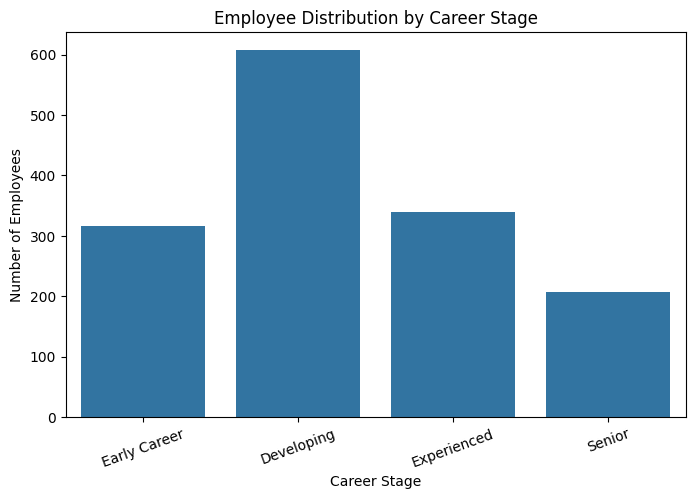

In [20]:


plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x='CareerStage')
plt.title('Employee Distribution by Career Stage')
plt.xlabel('Career Stage')
plt.ylabel('Number of Employees')
plt.xticks(rotation=20)
plt.show()

In [21]:


numerical_features = df_clean.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

outlier_summary = {}

for column in numerical_features:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ]

    outlier_summary[column] = len(outliers)

print("Number of outliers detected by feature:")
for column, count in outlier_summary.items():
    if count > 0:
        print(f"{column}: {count}")

Number of outliers detected by feature:
MonthlyIncome: 114
NumCompaniesWorked: 52
PerformanceRating: 226
StockOptionLevel: 85
TotalWorkingYears: 63
TrainingTimesLastYear: 238
YearsAtCompany: 104
YearsInCurrentRole: 21
YearsSinceLastPromotion: 107
YearsWithCurrManager: 14


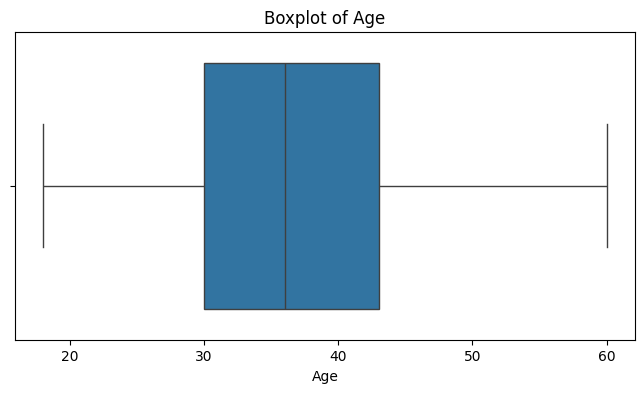

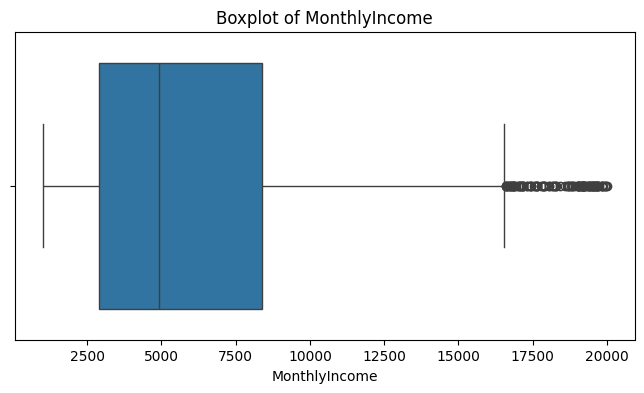

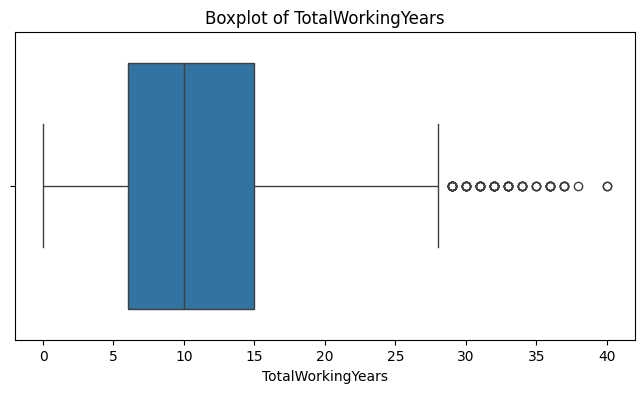

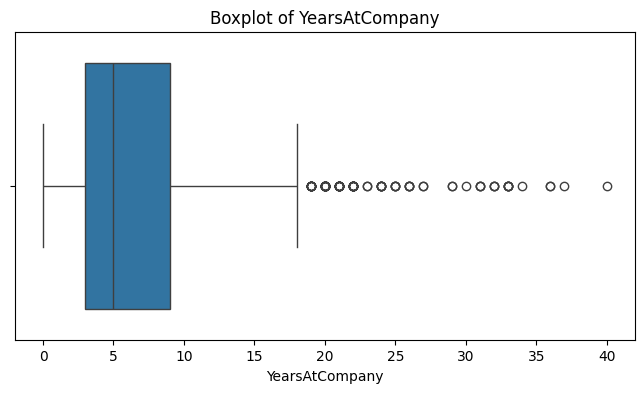

In [22]:


features_to_plot = [
    'Age',
    'MonthlyIncome',
    'TotalWorkingYears',
    'YearsAtCompany'
]

for column in features_to_plot:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df_clean[column])
    plt.title(f'Boxplot of {column}')
    plt.xlabel(column)
    plt.show()

In [23]:


X = df_clean.drop('Attrition', axis=1)
y = df_clean['Attrition']

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget values:")
print(y.value_counts())

Features shape: (1470, 32)
Target shape: (1470,)

Target values:
Attrition
No     1233
Yes     237
Name: count, dtype: int64


In [24]:


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (1176, 32)
Testing set: (294, 32)


In [25]:


numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Number of numerical features: 24
Number of categorical features: 8

Numerical features:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'CompanyExperienceRatio']

Categorical features:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime', 'CareerStage']


In [26]:


numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [27]:


X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (1176, 56)
Testing data after preprocessing: (294, 56)


In [28]:
feature_names = preprocessor.get_feature_names_out()

print("Total processed features:", len(feature_names))
print("\nFirst 20 processed features:")
print(feature_names[:20])

Total processed features: 56

First 20 processed features:
['num__Age' 'num__DailyRate' 'num__DistanceFromHome' 'num__Education'
 'num__EnvironmentSatisfaction' 'num__HourlyRate' 'num__JobInvolvement'
 'num__JobLevel' 'num__JobSatisfaction' 'num__MonthlyIncome'
 'num__MonthlyRate' 'num__NumCompaniesWorked' 'num__PercentSalaryHike'
 'num__PerformanceRating' 'num__RelationshipSatisfaction'
 'num__StockOptionLevel' 'num__TotalWorkingYears'
 'num__TrainingTimesLastYear' 'num__WorkLifeBalance' 'num__YearsAtCompany']


In [29]:
X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

print("Processed training data:")
display(X_train_processed_df.head())

Processed training data:


,num__Age,num__DailyRate,num__DistanceFromHome,num__Education,num__EnvironmentSatisfaction,num__HourlyRate,num__JobInvolvement,num__JobLevel,num__JobSatisfaction,num__MonthlyIncome,...,cat__JobRole_Sales Representative,cat__MaritalStatus_Divorced,cat__MaritalStatus_Married,cat__MaritalStatus_Single,cat__OverTime_No,cat__OverTime_Yes,cat__CareerStage_Developing,cat__CareerStage_Early Career,cat__CareerStage_Experienced,cat__CareerStage_Senior
1194,1.090194,1.049455,-0.899915,1.064209,-0.658710,-0.908436,1.795282,1.762189,-0.647997,2.026752,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
128,-1.634828,-0.523449,-0.899915,-1.855332,0.260202,1.694111,0.373564,-0.986265,1.153526,-0.864408,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
810,0.981193,-0.992080,-0.777610,-1.855332,-1.577622,-0.662913,0.373564,1.762189,0.252765,2.347706,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
478,-1.307825,-0.453653,0.445433,-1.855332,-0.658710,-1.252169,0.373564,-0.986265,0.252765,-0.956202,...,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
491,0.654191,0.491086,-0.043784,2.037390,1.179114,0.319180,0.373564,-0.070114,0.252765,-0.185956,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0


In [30]:
joblib.dump(preprocessor, "preprocessor.pkl")

print("Preprocessing pipeline saved successfully as preprocessor.pkl")

Preprocessing pipeline saved successfully as preprocessor.pkl


In [31]:
loaded_preprocessor = joblib.load("preprocessor.pkl")

X_test_reloaded = loaded_preprocessor.transform(X_test)

print("Pipeline reloaded successfully!")
print("Reloaded test data shape:", X_test_reloaded.shape)

Pipeline reloaded successfully!
Reloaded test data shape: (294, 56)


In [32]:
salary_data = df_clean[['MonthlyIncome']].copy()

standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

salary_data['StandardScaler'] = standard_scaler.fit_transform(
    salary_data[['MonthlyIncome']]
)

salary_data['MinMaxScaler'] = minmax_scaler.fit_transform(
    salary_data[['MonthlyIncome']]
)

print("Scaling comparison:")
display(salary_data.head(10))

Scaling comparison:


,MonthlyIncome,StandardScaler,MinMaxScaler
0,5993,-0.108350,0.262454
1,5130,-0.291719,0.217009
2,2090,-0.937654,0.056925
3,2909,-0.763634,0.100053
4,3468,-0.644858,0.129489
5,3068,-0.729850,0.108425
6,2670,-0.814416,0.087467
7,2693,-0.809529,0.088678
8,9526,0.642338,0.448499
9,5237,-0.268983,0.222643


In [33]:
print("Original MonthlyIncome range:")
print(
    salary_data['MonthlyIncome'].min(),
    "to",
    salary_data['MonthlyIncome'].max()
)

print("\nStandardScaler range:")
print(
    salary_data['StandardScaler'].min(),
    "to",
    salary_data['StandardScaler'].max()
)

print("\nMinMaxScaler range:")
print(
    salary_data['MinMaxScaler'].min(),
    "to",
    salary_data['MinMaxScaler'].max()
)

Original MonthlyIncome range:
1009 to 19999

StandardScaler range:
-1.1673431137498147 to 2.8676264826669864

MinMaxScaler range:
0.0 to 1.0000000000000002


In [34]:
from sklearn.preprocessing import LabelEncoder

example_data = df_clean[['BusinessTravel']].copy()

label_encoder = LabelEncoder()
example_data['Label_Encoded'] = label_encoder.fit_transform(
    example_data['BusinessTravel']
)

print("Label Encoding:")
display(example_data.head(10))

Label Encoding:


,BusinessTravel,Label_Encoded
0,Travel_Rarely,2
1,Travel_Frequently,1
2,Travel_Rarely,2
3,Travel_Frequently,1
4,Travel_Rarely,2
5,Travel_Frequently,1
6,Travel_Rarely,2
7,Travel_Rarely,2
8,Travel_Frequently,1
9,Travel_Rarely,2


In [35]:
onehot_encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown='ignore'
)

onehot_result = onehot_encoder.fit_transform(
    df_clean[['BusinessTravel']]
)

onehot_columns = onehot_encoder.get_feature_names_out(
    ['BusinessTravel']
)

onehot_df = pd.DataFrame(
    onehot_result,
    columns=onehot_columns
)

print("One-Hot Encoding:")
display(onehot_df.head(10))

One-Hot Encoding:


,BusinessTravel_Non-Travel,BusinessTravel_Travel_Frequently,BusinessTravel_Travel_Rarely
0,0.0,0.0,1.0
1,0.0,1.0,0.0
2,0.0,0.0,1.0
3,0.0,1.0,0.0
4,0.0,0.0,1.0
5,0.0,1.0,0.0
6,0.0,0.0,1.0
7,0.0,0.0,1.0
8,0.0,1.0,0.0
9,0.0,0.0,1.0


In [36]:
print("Final preprocessing pipeline:")
print(preprocessor)

Final preprocessing pipeline:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Age', 'DailyRate', 'DistanceFromHome',
                                  'Education', 'EnvironmentSatisfaction',
                                  'HourlyRate', 'JobInvolvement', 'JobLevel',
                                  'JobSatisfaction', 'MonthlyIncome',
                                  'MonthlyRate', 'NumCompaniesWorked',
                                  'PercentSalaryHike', 'PerformanceRa...
                                  'YearsAtCompany', 'YearsInCurrentRole',
                                  'YearsSinceLastPromotion',
                                  'YearsWithCurrManager',
                                  'CompanyExperienceRatio']),
        

In [37]:
df_clean.to_csv("employee_attrition_clean.csv", index=False)

print("Final cleaned dataset saved successfully!")
print("Shape:", df_clean.shape)
print("\nColumns:")
print(df_clean.columns.tolist())

Final cleaned dataset saved successfully!
Shape: (1470, 33)

Columns:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'CompanyExperienceRatio', 'CareerStage']


In [38]:
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

print("\nFinal dataset shape:")
print(df_clean.shape)

print("\nFinal dataset preview:")
display(df_clean.head())

Missing values: 0
Duplicate rows: 0

Final dataset shape:
(1470, 33)

Final dataset preview:


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,CompanyExperienceRatio,CareerStage
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,0,8,0,1,6,4,0,5,0.750000,Developing
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,1,10,3,3,10,7,1,7,1.000000,Developing
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,0,7,3,3,0,0,0,0,0.000000,Developing
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,0,8,3,3,8,7,3,0,1.000000,Developing
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,1,6,3,3,2,2,2,2,0.333333,Developing


In [39]:
%%writefile preprocessing_pipeline.py

import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer



df = pd.read_csv("employee_attrition_raw.csv")

print("Original dataset shape:", df.shape)


columns_to_drop = [
    'EmployeeCount',
    'EmployeeNumber',
    'Over18',
    'StandardHours'
]

df_clean = df.drop(columns=columns_to_drop)


df_clean['CompanyExperienceRatio'] = (
    df_clean['YearsAtCompany'] /
    df_clean['TotalWorkingYears'].replace(0, np.nan)
)

df_clean['CompanyExperienceRatio'] = (
    df_clean['CompanyExperienceRatio'].fillna(0)
)

df_clean['CareerStage'] = pd.cut(
    df_clean['TotalWorkingYears'],
    bins=[-1, 5, 10, 20, np.inf],
    labels=[
        'Early Career',
        'Developing',
        'Experienced',
        'Senior'
    ]
)



X = df_clean.drop('Attrition', axis=1)
y = df_clean['Attrition']


numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()



numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)



X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)




X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)



df_clean.to_csv(
    "employee_attrition_clean.csv",
    index=False
)

joblib.dump(
    preprocessor,
    "preprocessor.pkl"
)


print("\nPreprocessing completed successfully!")
print("Clean dataset shape:", df_clean.shape)
print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)
print("Saved: employee_attrition_clean.csv")
print("Saved: preprocessor.pkl")

Writing preprocessing_pipeline.py


In [41]:
!pip install reportlab


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 23.8 MB/s eta 0:00:00


In [42]:
from reportlab.lib.pagesizes import A4
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER

print("ReportLab imported successfully!")

ReportLab imported successfully!


In [44]:
import os

print("PDF exists:", os.path.exists("Preprocessing_Report.pdf"))

if os.path.exists("Preprocessing_Report.pdf"):
    print("File size:", os.path.getsize("Preprocessing_Report.pdf"), "bytes")

PDF exists: False


In [45]:
from reportlab.lib.pagesizes import A4
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER

report_file = "Preprocessing_Report.pdf"

doc = SimpleDocTemplate(
    report_file,
    pagesize=A4,
    rightMargin=40,
    leftMargin=40,
    topMargin=40,
    bottomMargin=40
)

styles = getSampleStyleSheet()

title_style = ParagraphStyle(
    "ReportTitle",
    parent=styles["Title"],
    alignment=TA_CENTER,
    spaceAfter=20
)

heading_style = ParagraphStyle(
    "ReportHeading",
    parent=styles["Heading2"],
    spaceBefore=12,
    spaceAfter=8
)

body_style = ParagraphStyle(
    "ReportBody",
    parent=styles["BodyText"],
    leading=15,
    spaceAfter=8
)

story = []

# TITLE
story.append(Paragraph(
    "Data Preprocessing, Feature Engineering & Machine Learning Pipeline Development",
    title_style
))

story.append(Paragraph(
    "<b>Dataset:</b> IBM HR Analytics Employee Attrition Dataset",
    body_style
))

# 1
story.append(Paragraph("1. Dataset Overview", heading_style))

story.append(Paragraph(
    "The dataset was loaded and inspected using Python, Pandas and NumPy. "
    "The original dataset contained 1,470 records and 35 columns. "
    "Attrition was used as the target variable for the machine learning workflow.",
    body_style
))

# 2
story.append(Paragraph("2. Data Quality Assessment", heading_style))

missing_count = int(df.isnull().sum().sum())
duplicate_count = int(df.duplicated().sum())

story.append(Paragraph(
    f"Missing values detected: <b>{missing_count}</b><br/>"
    f"Duplicate records detected: <b>{duplicate_count}</b>",
    body_style
))

story.append(Paragraph(
    "The dataset was checked for missing values, duplicate records, "
    "data types and categorical values before preprocessing.",
    body_style
))

# 3
story.append(Paragraph("3. Data Cleaning", heading_style))

story.append(Paragraph(
    "The following columns were removed because they were constant or "
    "identifier-related and were not useful as predictive features:",
    body_style
))

cleaning_data = [
    ["Column", "Reason"],
    ["EmployeeCount", "Constant value"],
    ["EmployeeNumber", "Employee identifier"],
    ["Over18", "Constant value"],
    ["StandardHours", "Constant value"]
]

table = Table(cleaning_data, colWidths=[160, 300])

table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.lightgrey),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 6),
    ("VALIGN", (0, 0), (-1, -1), "TOP")
]))

story.append(table)

# 4
story.append(Paragraph("4. Feature Engineering", heading_style))

story.append(Paragraph(
    "<b>CompanyExperienceRatio:</b> Created by dividing YearsAtCompany "
    "by TotalWorkingYears. Zero was used when TotalWorkingYears was zero "
    "to avoid division by zero.",
    body_style
))

story.append(Paragraph(
    "<b>CareerStage:</b> TotalWorkingYears was grouped into Early Career, "
    "Developing, Experienced and Senior categories.",
    body_style
))

# 5
story.append(Paragraph("5. Outlier Detection", heading_style))

story.append(Paragraph(
    "Potential outliers were identified using the Interquartile Range (IQR) "
    "method and visualized using box plots. Age, MonthlyIncome, "
    "TotalWorkingYears and YearsAtCompany were examined. Extreme observations "
    "were reviewed rather than automatically deleted because they may represent "
    "legitimate employee observations.",
    body_style
))

# 6
story.append(Paragraph("6. Categorical Encoding", heading_style))

story.append(Paragraph(
    "One-Hot Encoding was used in the final preprocessing pipeline for "
    "categorical features. The encoder was configured with "
    "handle_unknown='ignore'. Label Encoding was also demonstrated separately "
    "for comparison.",
    body_style
))

# 7
story.append(Paragraph("7. Feature Scaling", heading_style))

story.append(Paragraph(
    "StandardScaler was used in the final numerical preprocessing pipeline. "
    "MinMaxScaler was also applied to MonthlyIncome as a comparison exercise. "
    "StandardScaler standardizes features around a mean of approximately zero, "
    "whereas MinMaxScaler maps values to a bounded range.",
    body_style
))

# 8
story.append(Paragraph("8. Machine Learning Pipeline", heading_style))

story.append(Paragraph(
    "A ColumnTransformer was created with separate numerical and categorical "
    "preprocessing workflows. Numerical features use median imputation followed "
    "by StandardScaler. Categorical features use most-frequent imputation "
    "followed by One-Hot Encoding.",
    body_style
))

story.append(Paragraph(
    "The data was divided into training and testing sets using an 80:20 ratio, "
    "random_state=42 and stratification based on Attrition. The preprocessing "
    "pipeline was fitted only on the training data and then applied to the "
    "testing data to reduce data leakage.",
    body_style
))

# 9
story.append(Paragraph("9. Saved Outputs", heading_style))

story.append(Paragraph(
    "The preprocessing pipeline was saved as <b>preprocessor.pkl</b>. "
    "The cleaned dataset was saved as <b>employee_attrition_clean.csv</b>. "
    "The implementation was saved as <b>preprocessing_pipeline.py</b>.",
    body_style
))

# 10
story.append(Paragraph("10. Assumptions and Limitations", heading_style))

story.append(Paragraph(
    "The preprocessing workflow was designed for preparation of the Employee "
    "Attrition dataset for subsequent machine learning. Preprocessing choices "
    "may need to be adjusted for other datasets or production environments. "
    "Potential outliers were reviewed rather than universally removed.",
    body_style
))

doc.build(story)

print("SUCCESS: Preprocessing_Report.pdf has been created.")

SUCCESS: Preprocessing_Report.pdf has been created.


In [46]:
import os

print("PDF exists:", os.path.exists("Preprocessing_Report.pdf"))

if os.path.exists("Preprocessing_Report.pdf"):
    print("File size:", os.path.getsize("Preprocessing_Report.pdf"), "bytes")

PDF exists: True
File size: 4530 bytes


In [47]:
from google.colab import files

files.download("Preprocessing_Report.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [48]:
import os

required_files = [
    "02_data_preprocessing.ipynb",
    "employee_attrition_clean.csv",
    "preprocessor.pkl",
    "preprocessing_pipeline.py",
    "Preprocessing_Report.pdf"
]

print("Checking required files:\n")

for file in required_files:
    print(
        "✅" if os.path.exists(file) else "❌",
        file
    )

Checking required files:

❌ 02_data_preprocessing.ipynb
✅ employee_attrition_clean.csv
✅ preprocessor.pkl
✅ preprocessing_pipeline.py
✅ Preprocessing_Report.pdf
